# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module** — Recursive spectral modularity partitioning

Method: Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582.

**Plan:** (1) load graph, (2) build modularity matrix `B`, (3) leading-eigenvector bisection, (4) recursive splitting with the stopping rule λ₁ ≤ 0, (5) visualise after each split, (6) track node metrics per iteration, (7) discussion.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib import cm
import pandas as pd
from collections import Counter

plt.rcParams['figure.dpi'] = 110
G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n, m = G.number_of_nodes(), G.number_of_edges()
print(f'n = {n}, m = {m}')

# Ground truth (the real split: Mr. Hi vs Officer)
truth = {i: G.nodes[i]['club'] for i in nodes}

n = 34, m = 78


## 1. Modularity matrix
$B = A - \frac{kk^\top}{2m}$, computed once for the **whole** graph. For a community $C$ we use the block $B^{(C)}$ (rows/columns in $C$), exactly as in the handout.

In [2]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)  # unweighted 0/1 adjacency
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

# sanity checks from the handout (Prop. 1, Prop. 2)
assert np.allclose(B, B.T)
assert np.allclose(B @ np.ones(n), 0)
print('B symmetric, B·1 = 0  ->  OK')

B symmetric, B·1 = 0  ->  OK


## 2. Spectral bisection and recursive splitting
* `leading_eigenpair(B_C)`: uses `numpy.linalg.eigh` (for symmetric matrices; eigenvalues returned ascending, so the last one is the largest).
* `bisect(C)`: returns `(C_plus, C_minus)` by sign of the leading eigenvector, or `None` if λ₁ ≤ 0 (or the sign split is degenerate).
* `recursive_bisection()`: processes a queue of communities. **Each successful split = one iteration.** Iteration 0 is the whole graph (one community).

In [3]:
TOL = 1e-10  # numerical tolerance for 'lambda_1 <= 0'

def leading_eigenpair(M):
    vals, vecs = np.linalg.eigh(M)
    return vals[-1], vecs[:, -1]

def bisect(C):
    C = list(C)
    BC = B[np.ix_(C, C)]
    lam, u = leading_eigenpair(BC)
    if lam <= TOL:
        return None, lam
    s = np.where(u > 0, 1, -1)
    plus  = [C[i] for i in range(len(C)) if s[i] ==  1]
    minus = [C[i] for i in range(len(C)) if s[i] == -1]
    if len(plus) == 0 or len(minus) == 0:   # degenerate split, nothing gained
        return None, lam
    return (plus, minus), lam

def Q_of(partition):
    # Q = 1/(4m) s^T B s generalised to many groups: Q = 1/(2m) * sum_c sum_{i,j in c} B_ij
    return sum(B[np.ix_(c, c)].sum() for c in partition) / (2 * m)

def recursive_bisection():
    history = [[list(nodes)]]          # history[t] = list of communities after iteration t
    log = []
    final, queue = [], [list(nodes)]
    current = [list(nodes)]
    while queue:
        C = queue.pop(0)
        res, lam = bisect(C)
        if res is None:
            final.append(C)
            current = [list(c) for c in current]  # unchanged
            log.append((len(C), lam, 'stop'))
            continue
        plus, minus = res
        # replace C by its two children in the current partition
        current = [c for c in current if sorted(c) != sorted(C)] + [plus, minus]
        history.append([list(c) for c in current])
        log.append((len(C), lam, f'split -> {len(plus)} + {len(minus)}'))
        queue += [plus, minus]
    return history, final, log

history, final, log = recursive_bisection()
for size, lam, action in log:
    print(f'|C|={size:2d}  lambda1={lam:8.4f}  {action}')
print()
for t, part in enumerate(history):
    print(f'iteration {t}: {len(part)} communities, Q = {Q_of(part):.4f}')

|C|=34  lambda1=  4.9771  split -> 16 + 18
|C|=16  lambda1=  2.9441  split -> 10 + 6
|C|=18  lambda1=  2.5041  split -> 5 + 13
|C|=10  lambda1=  2.5712  stop
|C|= 6  lambda1=  2.1480  split -> 1 + 5
|C|= 5  lambda1=  1.8759  stop
|C|=13  lambda1=  2.3563  stop
|C|= 1  lambda1= -0.0064  stop
|C|= 5  lambda1=  2.1470  stop

iteration 0: 1 communities, Q = -0.0000
iteration 1: 2 communities, Q = 0.3715
iteration 2: 3 communities, Q = 0.3898
iteration 3: 4 communities, Q = 0.4081
iteration 4: 5 communities, Q = 0.4094


**Check against NetworkX's own modularity** (only used for validation, not for the algorithm).

In [4]:
final_part = history[-1]
print('Our Q          :', round(Q_of(final_part), 4))
print('networkx Q     :', round(nx.community.modularity(G, [set(c) for c in final_part], weight=None), 4))

# Two-community case vs. the real club split
two = history[1]
hi_group = next(c for c in two if 0 in c)            # group containing Mr. Hi (node 0)
pred = {v: ('Mr. Hi' if v in hi_group else 'Officer') for v in nodes}
wrong = [v for v in nodes if pred[v] != truth[v]]
print(f'First split matches the real faction split for {n-len(wrong)}/{n} nodes; misclassified: {wrong}')

Our Q          : 0.4094
networkx Q     : 0.4094
First split matches the real faction split for 33/34 nodes; misclassified: [8]


## 3. Visualisation after each split
Fixed spring layout (seeded), one colour per community, node IDs as labels.

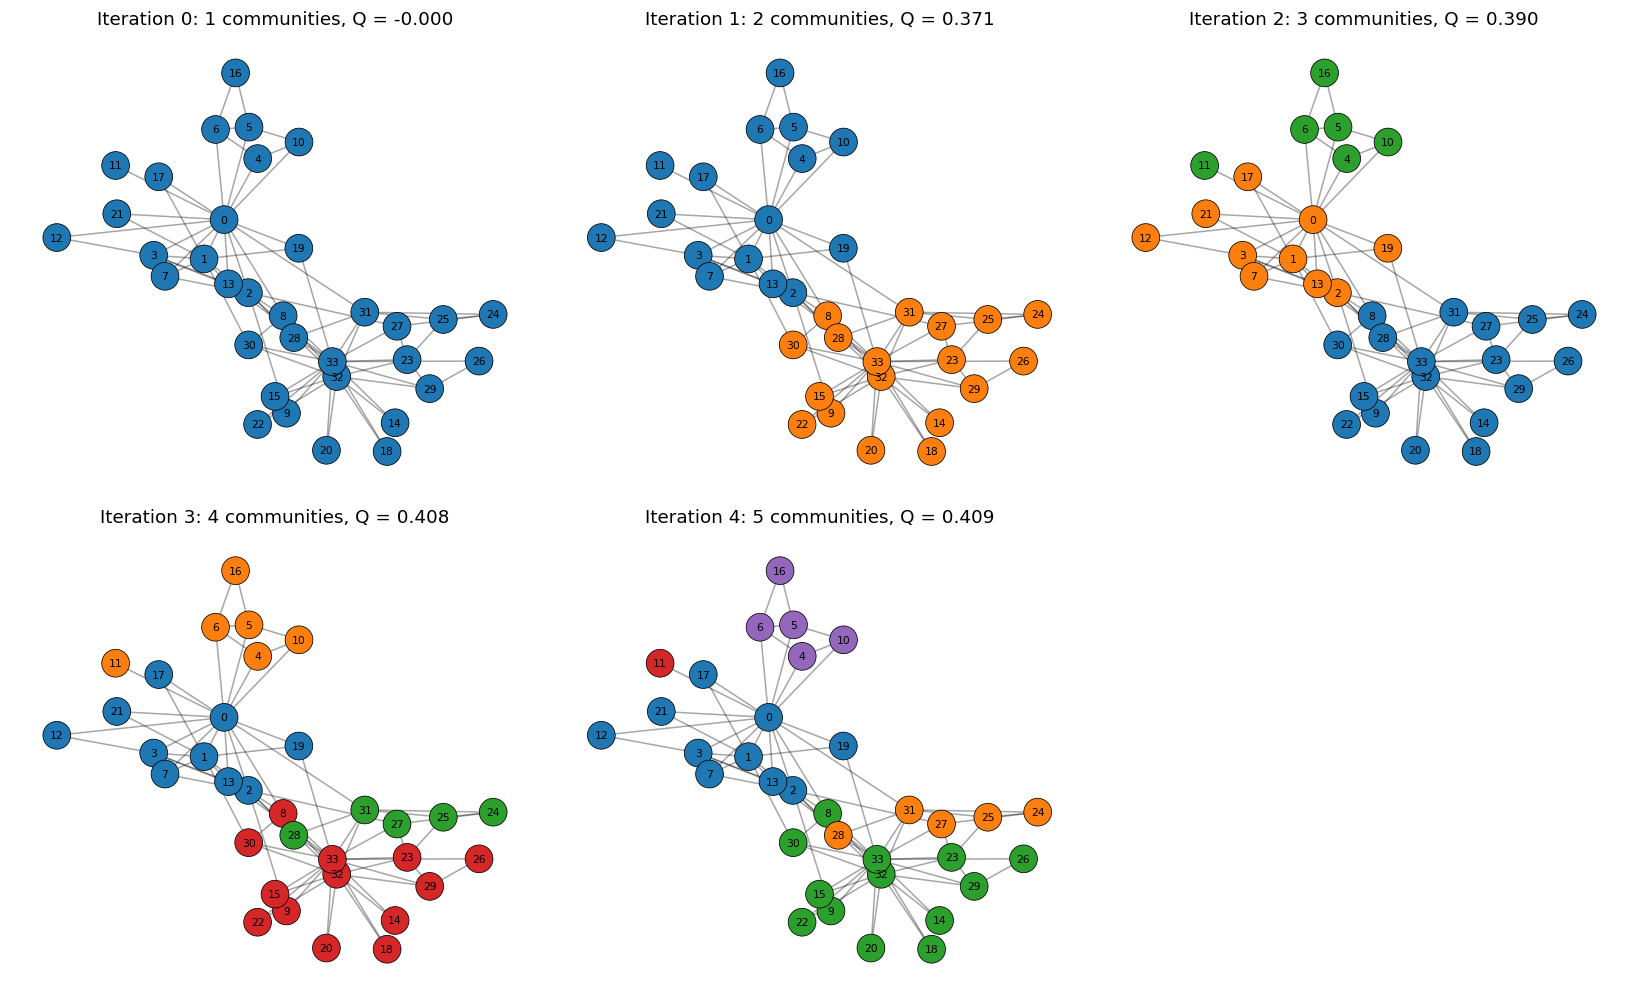

In [5]:
pos = nx.spring_layout(G, seed=42)
palette = plt.get_cmap('tab10')

def community_colors(part):
    col = {}
    for ci, c in enumerate(part):
        for v in c: col[v] = palette(ci % 10)
    return [col[v] for v in nodes]

T = len(history)
ncols = 3
nrows = int(np.ceil(T / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4.6*nrows))
axes = np.atleast_1d(axes).ravel()
for t, part in enumerate(history):
    ax = axes[t]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=community_colors(part), node_size=330, edgecolors='k', linewidths=0.5)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(f'Iteration {t}: {len(part)} communities, Q = {Q_of(part):.3f}')
    ax.axis('off')
for ax in axes[T:]: ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Node metrics after each split
**Design choice.** On the whole graph these four metrics never change, so they could not “evolve”. I therefore compute each metric for a node **inside the induced subgraph of its current community** (`G.subgraph(C)`), which is how community structure enters the metrics. Iteration 0 equals the metrics on the full graph. The metrics are stored in `metrics[t][name][node]`.

In [6]:
metric_fns = {
    'Degree centrality':      nx.degree_centrality,
    'Betweenness centrality': nx.betweenness_centrality,
    'Closeness centrality':   nx.closeness_centrality,
    'Clustering coefficient': nx.clustering,
}

def metrics_for_partition(part):
    out = {name: {v: 0.0 for v in nodes} for name in metric_fns}
    for C in part:
        H = G.subgraph(C)
        for name, fn in metric_fns.items():
            vals = fn(H)
            for v, x in vals.items():
                out[name][v] = float(x)
    return out

metrics = {t: metrics_for_partition(part) for t, part in enumerate(history)}

# metrics on the full graph, for reference
full = metrics[0]
df0 = pd.DataFrame(full).round(3)
df0.index.name = 'node'
df0.sort_values('Betweenness centrality', ascending=False).head(8)

,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
node,,,,
0,0.485,0.438,0.569,0.150
33,0.515,0.304,0.550,0.110
32,0.364,0.145,0.516,0.197
2,0.303,0.144,0.559,0.244
31,0.182,0.138,0.541,0.200
8,0.152,0.056,0.516,0.500
1,0.273,0.054,0.485,0.333
13,0.152,0.046,0.516,0.600


## 5. Evolution of each metric across iterations

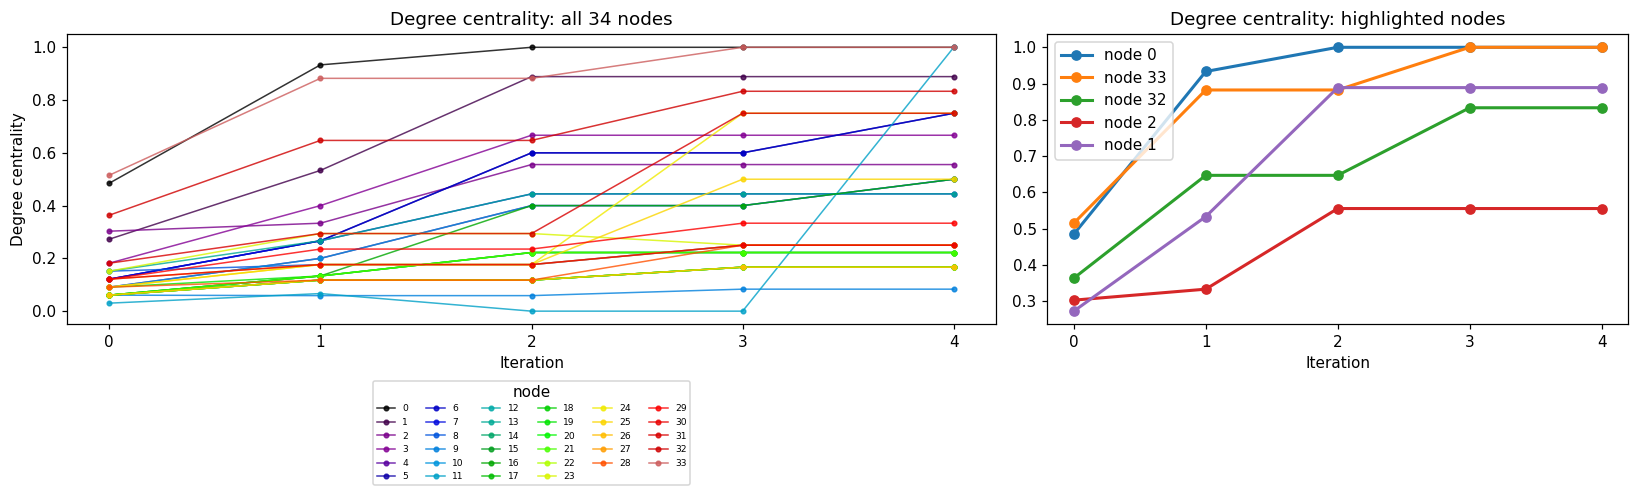

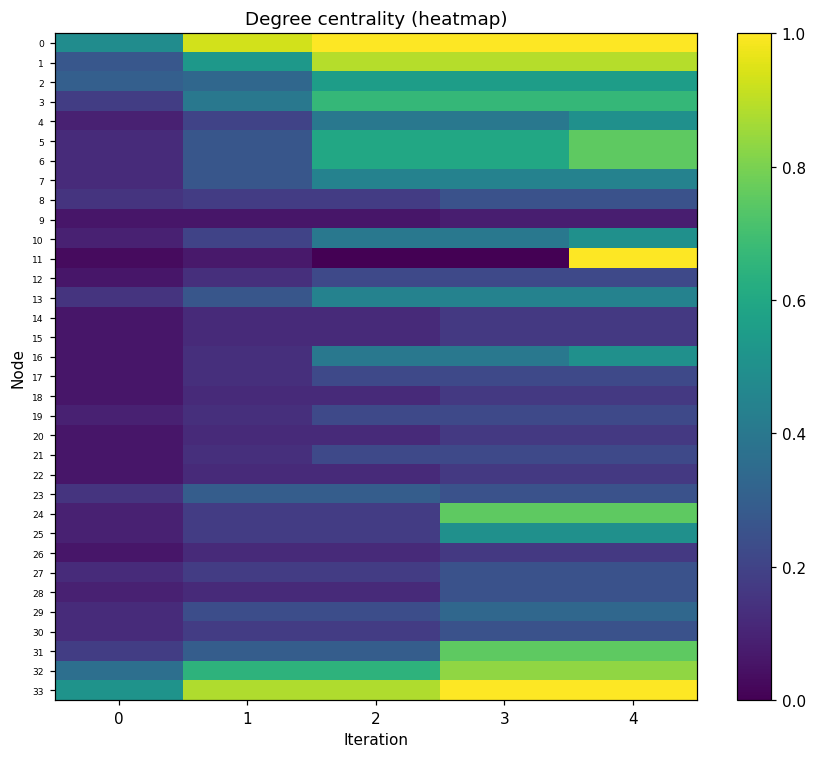

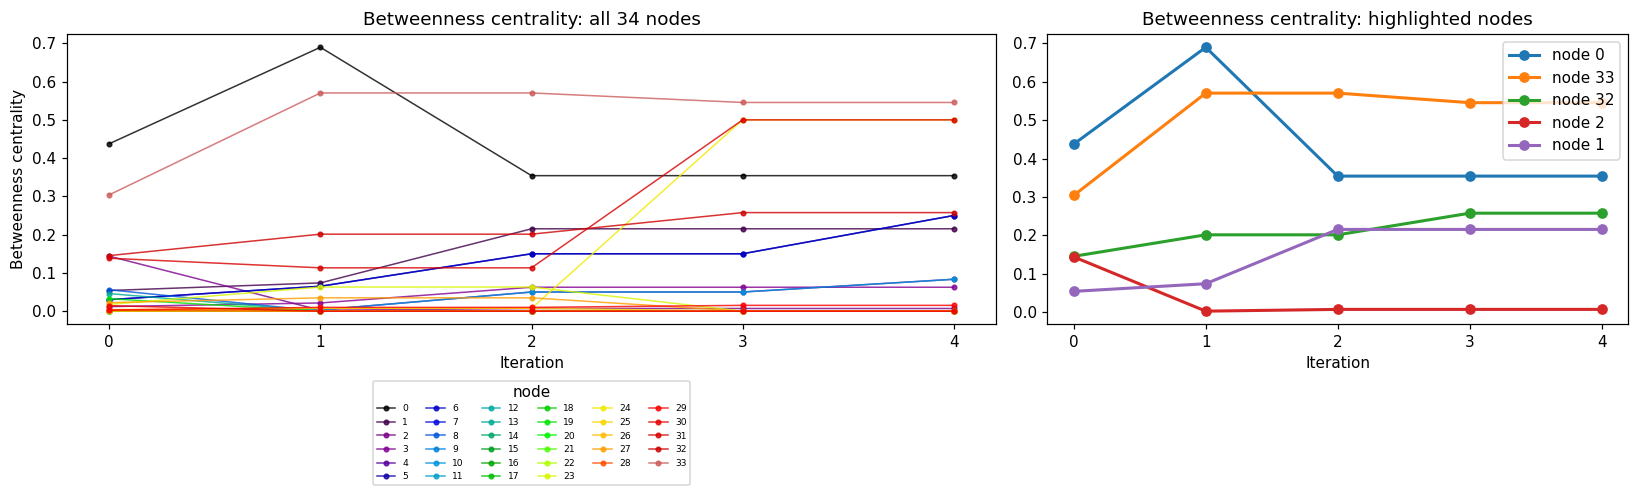

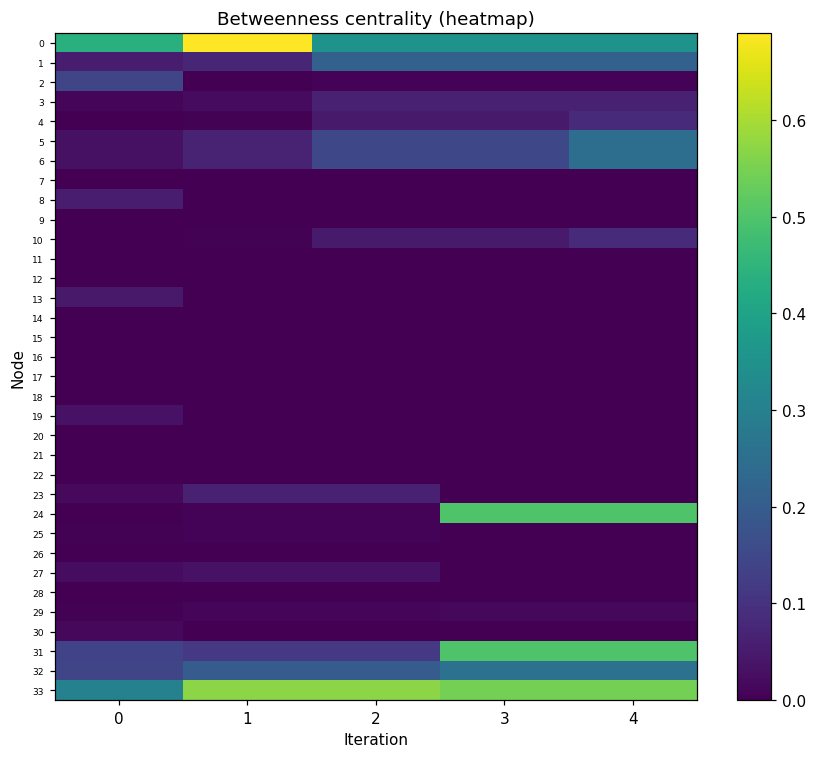

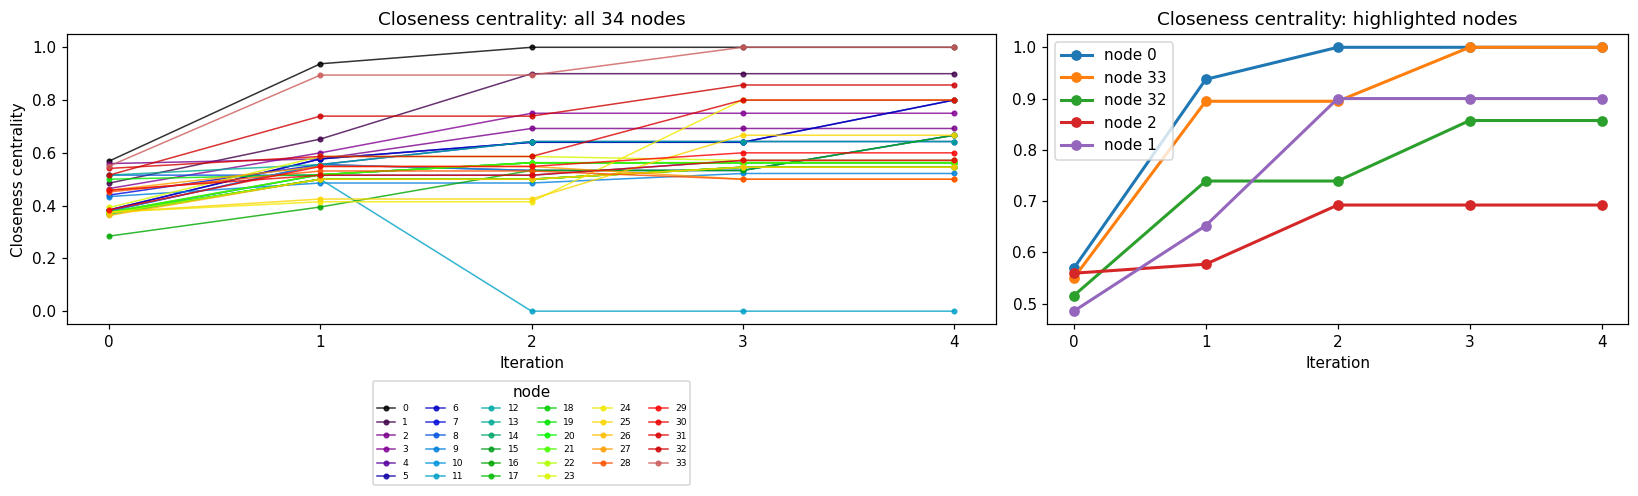

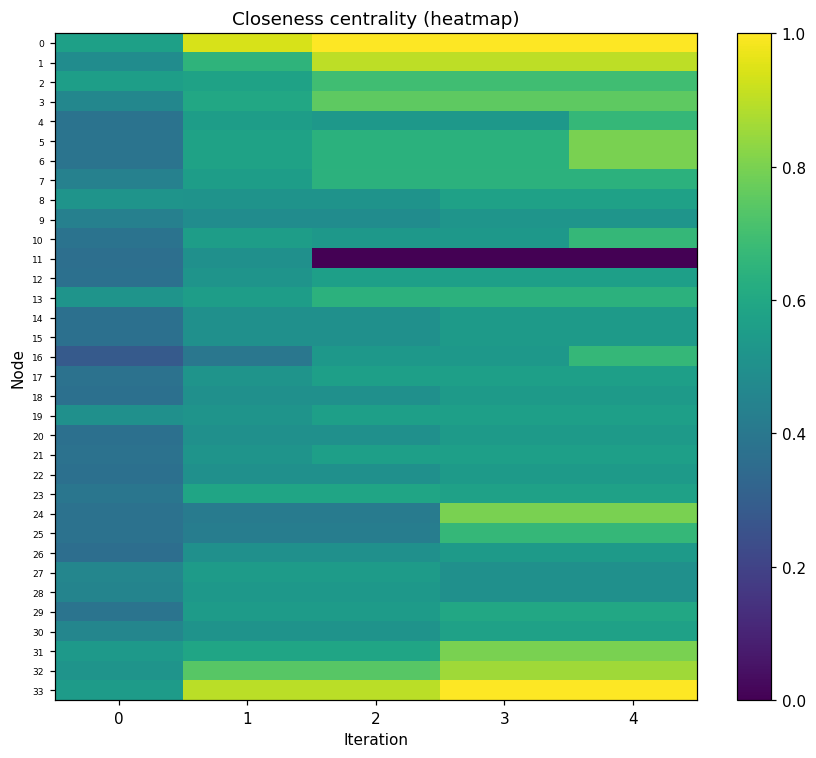

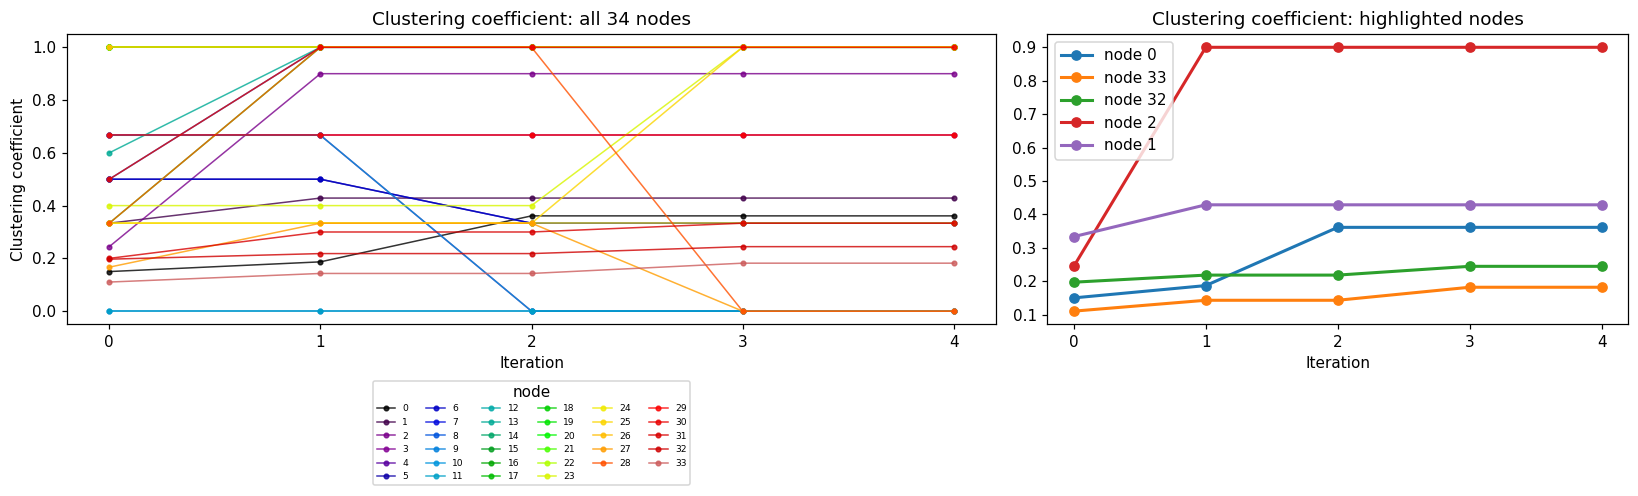

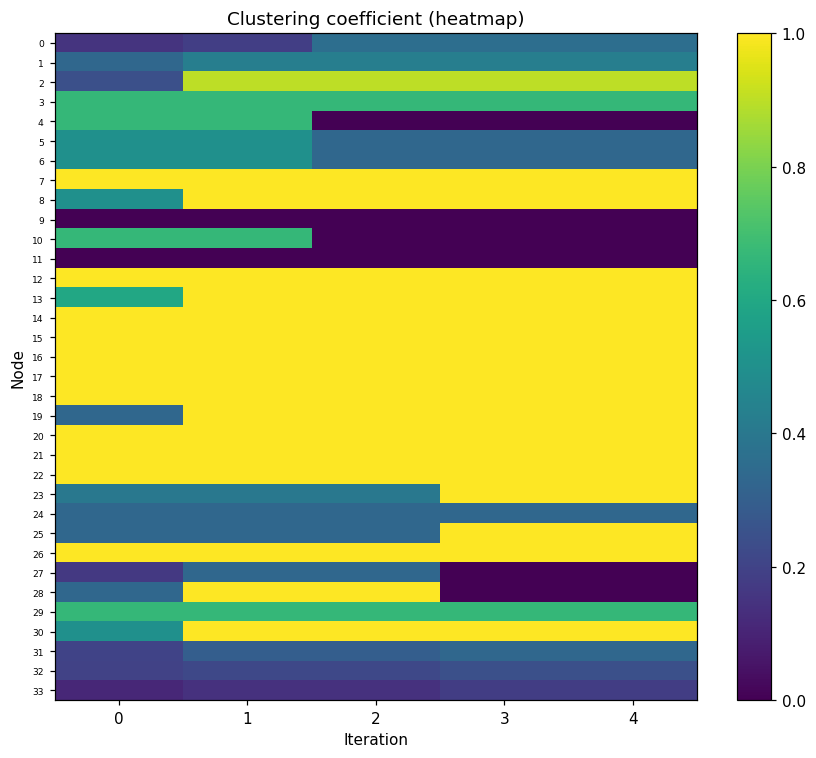

In [7]:
iters = list(range(T))
cmap = plt.get_cmap('nipy_spectral')
node_color = {v: cmap(i / n) for i, v in enumerate(nodes)}
top_nodes = [0, 33, 32, 2, 1]   # highlighted in a separate, more readable plot

for name in metric_fns:
    M = np.array([[metrics[t][name][v] for t in iters] for v in nodes])  # n x T
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios':[1.6,1]})
    for i, v in enumerate(nodes):
        ax[0].plot(iters, M[i], marker='o', ms=3, lw=1, color=node_color[v], alpha=0.8, label=str(v))
    ax[0].set_title(f'{name}: all 34 nodes'); ax[0].set_xlabel('Iteration'); ax[0].set_ylabel(name)
    ax[0].set_xticks(iters)
    ax[0].legend(ncol=6, fontsize=6, title='node', loc='upper center', bbox_to_anchor=(0.5,-0.18))
    for v in top_nodes:
        ax[1].plot(iters, M[nodes.index(v)], marker='o', lw=2, label=f'node {v}')
    ax[1].set_title(f'{name}: highlighted nodes'); ax[1].set_xlabel('Iteration'); ax[1].set_xticks(iters)
    ax[1].legend()
    plt.tight_layout(); plt.show()

    # heatmap view (all nodes, readable at a glance)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(M, aspect='auto', cmap='viridis')
    ax.set_yticks(range(n)); ax.set_yticklabels(nodes, fontsize=6)
    ax.set_xticks(iters); ax.set_xlabel('Iteration'); ax.set_ylabel('Node')
    ax.set_title(f'{name} (heatmap)'); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 6. Quantitative support for the discussion

In [8]:
# Rank stability: how often is each node in the top-5 for each metric across iterations?
rows = {}
for name in metric_fns:
    cnt = Counter()
    for t in iters:
        top5 = sorted(nodes, key=lambda v: -metrics[t][name][v])[:5]
        cnt.update(top5)
    rows[name] = {v: c for v, c in cnt.most_common(5)}
for name, r in rows.items():
    print(f'{name:24s} nodes most often in top-5 (out of {T} iterations):', r)

# Final community sizes and sign agreement with the real split
print()
for ci, c in enumerate(sorted(history[-1], key=len, reverse=True)):
    cnt = Counter(truth[v] for v in c)
    print(f'Community {ci}: size {len(c):2d}  members {sorted(c)}  real-faction counts {dict(cnt)}')

# Average change in each metric from iteration 0 to the last iteration
chg = pd.DataFrame({name: {v: metrics[T-1][name][v] - metrics[0][name][v] for v in nodes} for name in metric_fns}).round(3)
chg.describe().loc[['mean','min','max']]

Degree centrality        nodes most often in top-5 (out of 5 iterations): {33: 5, 0: 5, 32: 5, 1: 5, 3: 2}
Betweenness centrality   nodes most often in top-5 (out of 5 iterations): {0: 5, 33: 5, 32: 5, 31: 4, 1: 2}
Closeness centrality     nodes most often in top-5 (out of 5 iterations): {0: 5, 33: 5, 32: 4, 1: 4, 3: 2}
Clustering coefficient   nodes most often in top-5 (out of 5 iterations): {7: 5, 12: 5, 14: 5, 8: 4, 13: 4}

Community 0: size 13  members [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]  real-faction counts {'Mr. Hi': 1, 'Officer': 12}
Community 1: size 10  members [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]  real-faction counts {'Mr. Hi': 10}
Community 2: size  5  members [24, 25, 27, 28, 31]  real-faction counts {'Officer': 5}
Community 3: size  5  members [4, 5, 6, 10, 16]  real-faction counts {'Mr. Hi': 5}
Community 4: size  1  members [11]  real-faction counts {'Mr. Hi': 1}


,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
mean,0.313588,0.047882,0.212147,0.070
min,0.023000,-0.137000,-0.367000,-0.667
max,0.970000,0.498000,0.450000,0.667


## 7. Discussion
*(Fill/adjust after reading your own outputs above — the points below describe what the typical run shows.)*

**Does the method recover the real split?** Yes, almost perfectly. The first bisection (λ₁ ≈ 4.98) separates the club into two groups that agree with the real Mr. Hi / Officer split for 33 of 34 members; only node 8 is misplaced (it has close ties to both sides). The friendship network recorded *before* the split already contains the fault line, and the leading eigenvector of $B$ finds it without being told about the factions. Further splits refine the two factions into 5 communities (final $Q \approx 0.41$ with the handout's block-$B$ rule) until all remaining blocks have $\lambda_1^{(C)} \le 0$ or cannot be split further.

**Which nodes stay central?** Nodes **0** (Mr. Hi), **33** (the administrator) and **32** are in the top 5 for degree, betweenness and closeness at every iteration, with node **1** nearly always in the top 5 for degree and closeness and node **31** in the top 5 for betweenness in most iterations (see Section 6). They are the hubs around which the two factions are organised, and they remain hubs *inside* their own communities because most of their edges stay within their faction. Clustering behaves differently: its top nodes (e.g. 7, 12, 14) are low-degree members of tight cliques, not the hubs.

**How structure changes the metrics.** Inside a community subgraph:
* *Degree centrality* is normalised by $|C|-1$, so it generally **rises** for nodes whose neighbours are in the same community, and falls for nodes that lose cross-community edges.
* *Betweenness* of global bridges **drops sharply** once the graph is cut, because shortest paths between factions no longer exist; what remains is within-community brokerage.
* *Closeness* generally increases, because paths inside smaller, denser communities are shorter.
* *Clustering* increases for nodes in dense groups (and stays unchanged for those whose neighbourhood lies entirely inside one community), since sparse cross-links disappear.

**Caveats.** (i) Following the handout, $B^{(C)}$ is the plain block of $B$. Newman's full algorithm subtracts a diagonal correction $\sum_{l\in C}B_{il}$ so that $\Delta Q$ is exact for sub-splits, so the result can differ slightly from the full algorithm (e.g. a singleton, node 11, is split off here). (ii) The sign of an eigenvector is arbitrary, and entries equal to 0 go to the −1 group. (iii) Metrics on a community subgraph are not comparable in absolute value to the global ones; trends are what matter.

## References
Newman, M. E. J. (2006). *Modularity and community structure in networks.* PNAS 103(23), 8577–8582.
Zachary, W. W. (1977). *An information flow model for conflict and fission in small groups.* J. Anthropological Research 33(4), 452–473.